[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/myway0101/see-read-explain-dl/blob/main/notebooks/ch05_xai.ipynb)

# 5장 설명 가능한 AI — 모델은 어디를 보았나 — 실습 노트북
『보고, 읽고, 설명하는 딥러닝 — Colab에서 직접 만들며 배우는 딥러닝 응용』

5장 본문에 나오는 코드를 순서대로 실행해 봅니다. 위에서부터 차례로 실행하세요.
- 5.2 오클루전: 사진 일부를 가리고 확률 변화 보기
- 5.5 tf-explain으로 Grad-CAM·오클루전 실행
- 더 알아보기: Grad-CAM 직접 구현
- 실습: 패치 크기, 다른 범주, 다른 층으로 바꿔 보기

> CPU로도 실행할 수 있지만, 메뉴 [런타임] → [런타임 유형 변경]에서 **T4 GPU**를 고르면 더 빠릅니다.

## 준비
`tf-explain` 라이브러리는 예전 케라스(Keras 2) 방식으로 만들어져, 지금 Colab의 케라스 3에서는 그대로 동작하지 않습니다.
그래서 **텐서플로를 불러오기 전에** 환경 변수 `TF_USE_LEGACY_KERAS`를 `1`로 정해 예전 케라스(`tf_keras`)를 쓰도록 합니다.
이 설정은 런타임마다 처음 한 번만 효과가 있으므로, 이미 텐서플로를 불러왔다면 [런타임] → [세션 다시 시작] 후 이 셀부터 다시 실행하세요.

In [1]:
!pip install -q tf-explain
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"   # 텐서플로를 불러오기 전에 설정한다

from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications import VGG16

# XAI 알고리즘을 불러오는 부분입니다.
from tf_explain.core.grad_cam import GradCAM
from tf_explain.core.occlusion_sensitivity import OcclusionSensitivity

# 이미지를 불러와 보여 주는 데 쓰는 라이브러리를 불러옵니다.
import glob
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

import numpy as np
import tensorflow as tf
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 사진과 사전학습 모델 준비
『모두의 딥러닝』 저장소에서 ImageNet 사진 5장(말티즈, 페르시안 고양이, 다람쥐원숭이, 그랜드 피아노, 요트)을 내려받습니다.

Cloning into 'data'...
remote: Enumerating objects: 36, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (29/29), done.
remote: Total 36 (delta 9), reused 26 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (36/36), 483.12 KiB | 14.21 MiB/s, done.
Resolving deltas: 100% (9/9), done.


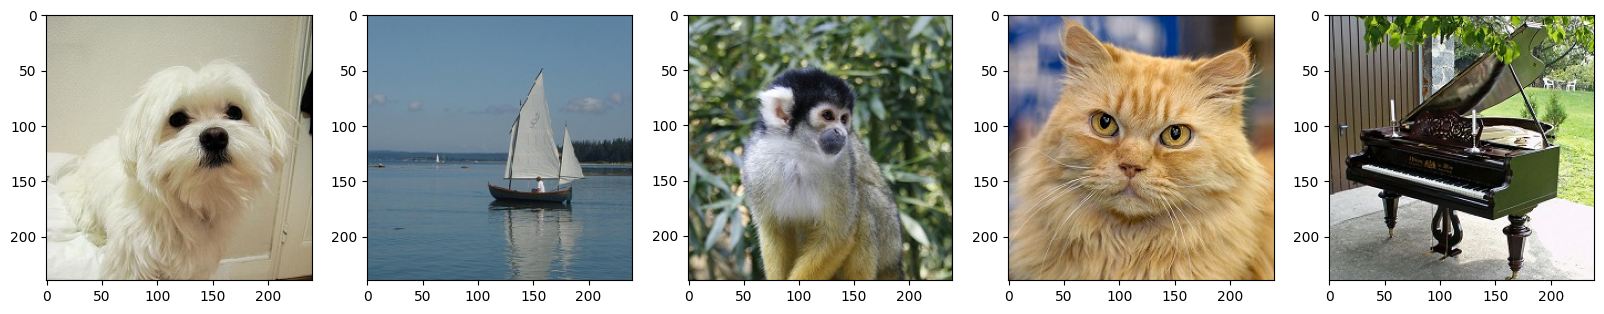

In [2]:
# 깃허브에 준비된 데이터를 가져옵니다.
!git clone https://github.com/taehojo/data.git

# 원본 이미지가 들어갈 리스트를 만듭니다.
images_originals = []

# 원본 이미지가 저장된 폴더에서 하나씩 불러와 리스트에 넣습니다.
for img_path in glob.glob('./data/img/*_0.jpg'):
    images_originals.append(mpimg.imread(img_path))

# 코랩에서 보여 줄 이미지의 크기
plt.figure(figsize=(20,20))

# 원본 이미지를 코랩에서 보이게 하기
for i, image_o in enumerate(images_originals):
    plt.subplot(5, 5, i+1)
    plt.imshow(image_o)

In [3]:
# 사전에 학습된 딥러닝 모델 불러오기
model = VGG16(weights="imagenet", include_top=True)

553467096/553467096 [==============================] - 9s 0us/step


### 모델이 맞히는지 먼저 확인하기
설명을 보기 전에, 모델이 각 사진을 무엇으로 예측하는지 확인합니다. 상위 3개 범주와 확률을 출력합니다.

In [4]:
from tensorflow.keras.applications.vgg16 import decode_predictions

# 원본 이미지 이름과 Imagenet에서의 해당 이미지 인덱스
input_list = ["maltese", "persian_cat", "squirrel_monkey", "grand_piano", "yawl"]
imagenet_index = ["153", "283", "382", "579", "914"]

for l in input_list:
    img = img_to_array(load_img('./data/img/{}_0.jpg'.format(l), target_size=(224,224)))
    pred = model.predict(img[np.newaxis], verbose=0)
    print(l, [(name, round(float(p), 3)) for _, name, p in decode_predictions(pred, top=3)[0]])

35363/35363 [==============================] - 0s 0us/step
maltese [('Maltese_dog', 0.997), ('Lhasa', 0.002), ('Shih-Tzu', 0.001)]
persian_cat [('Persian_cat', 0.969), ('lynx', 0.03), ('tiger_cat', 0.0)]
squirrel_monkey [('squirrel_monkey', 0.403), ('titi', 0.293), ('patas', 0.177)]
grand_piano [('grand_piano', 1.0), ('upright', 0.0), ('pool_table', 0.0)]
yawl [('yawl', 0.877), ('schooner', 0.102), ('trimaran', 0.008)]


## 5.2 오클루전 직접 해 보기
말티즈 사진의 얼굴(눈과 코)을 가린 경우와 배경을 가린 경우, 말티즈(153번) 확률이 어떻게 바뀌는지 봅니다.

original             Maltese 확률: 0.9968
face covered         Maltese 확률: 0.2735
background covered   Maltese 확률: 0.9967


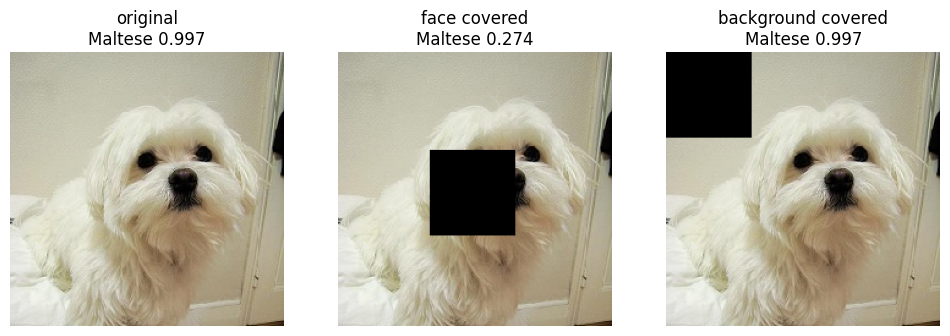

In [5]:
img = img_to_array(load_img('./data/img/maltese_0.jpg', target_size=(224,224)))

def maltese_prob(x):
    return float(model.predict(x[np.newaxis], verbose=0)[0][153])

cases = {'original': None, 'face covered': (80, 75), 'background covered': (0, 0)}   # 가릴 위치 (위, 왼쪽)
plt.figure(figsize=(12, 4))
for k, (name, pos) in enumerate(cases.items()):
    x = img.copy()
    if pos is not None:
        r, c = pos
        x[r:r+70, c:c+70] = 0          # 70x70 픽셀을 검게 가린다
    p = maltese_prob(x)
    print(f"{name:<20} Maltese 확률: {p:.4f}")
    plt.subplot(1, 3, k+1); plt.imshow(x.astype('uint8')); plt.title(f"{name}\nMaltese {p:.3f}"); plt.axis('off')
plt.show()

## 5.5 tf-explain으로 Grad-CAM 실행

In [6]:
# 그레이디언트 CAM 알고리즘 선택
explainer = GradCAM()

# 그레이디언트 CAM 알고리즘이 적용된 이미지가 들어갈 빈 리스트 만들기
images_cams = []

# 그레이디언트 CAM 알고리즘 실행
for l, i in zip(input_list, imagenet_index):
    # 이미지를 불러오고 내부에서 처리될 이미지의 크기를 설정합니다.
    img = load_img('./data/img/{}_0.jpg'.format(l), target_size=(224,224))
    img = img_to_array(img) # 이미지를 넘파이 배열로 바꿉니다.
    data = ([img], None)
    # 그레이디언트 CAM이 실행되는 부분입니다.
    grid = explainer.explain(data, model, int(i))
    # 실행 후 저장되는 이름입니다.
    explainer.save(grid, ".", './data/img/{}_cam.jpg'.format(l))

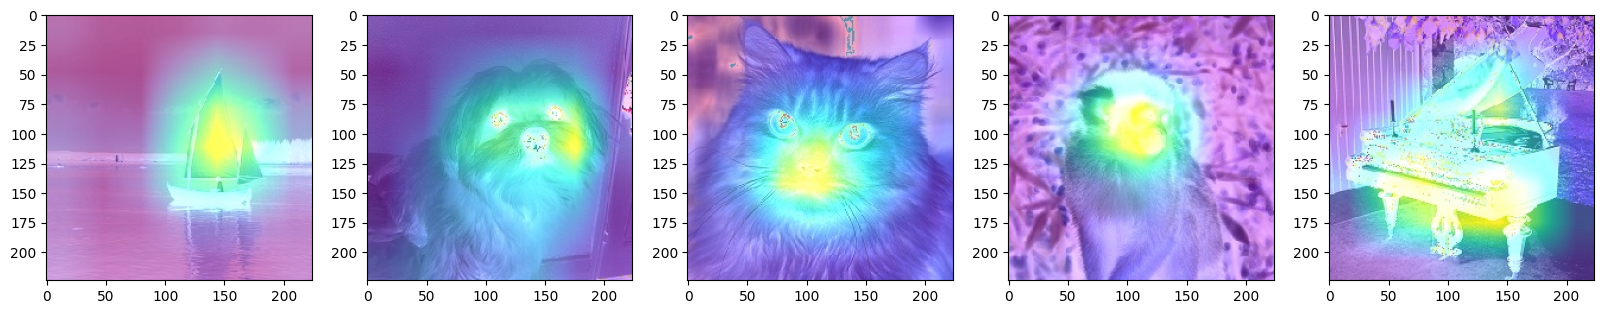

In [7]:
# 그레이디언트 CAM 알고리즘이 적용된 이미지를 불러오는 부분의 시작입니다.
plt.figure(figsize=(20,20))

for img_path in glob.glob('./data/img/*_cam.jpg'):
    images_cams.append(mpimg.imread(img_path))

for i, image_c in enumerate(images_cams):
    plt.subplot(5, 5, i+1)
    plt.imshow(image_c)

> 히트맵 뒤 사진의 배경색이 원본과 다르게 얼룩덜룩한 것은 표시 과정의 문제입니다. `tf-explain`은 사진 값이 0~1이라고 가정하고 255를 곱해 그리는데, 여기서는 0~255 사진을 넣었기 때문에 값이 넘칩니다. 히트맵 자체는 올바르게 계산됩니다. 깨끗한 그림이 필요하면 `GradCAM`의 `explain()`에 `image_weight=0`을 넣어 히트맵만 받은 뒤 원본과 직접 겹치세요.

## 5.5 tf-explain으로 오클루전 실행

2/2 [==============================] - 0s 110ms/step


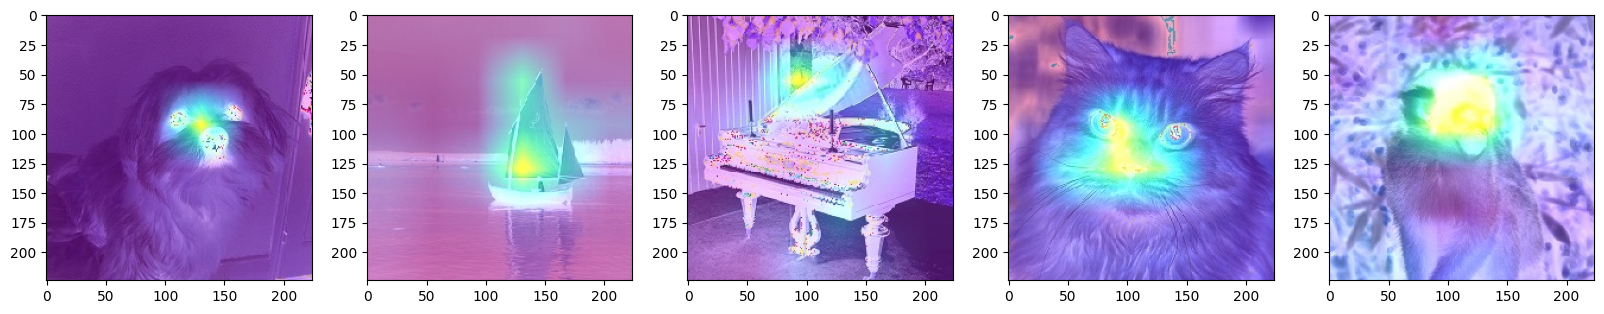

In [8]:
# 오클루전 알고리즘 선택
explainer = OcclusionSensitivity()

# 알고리즘이 적용된 이미지가 들어갈 빈 리스트 만들기
images_occ1s = []

# 패치 크기를 정합니다.
patch_size = 40

# 오클루전 알고리즘 실행
for l, i in zip(input_list, imagenet_index):
    img = load_img('./data/img/{}_0.jpg'.format(l), target_size=(224,224))
    img = img_to_array(img)
    data = ([img], None)
    # 패치 크기 설정이 추가됩니다.
    grid = explainer.explain(data, model, int(i), patch_size)
    explainer.save(grid, ".", './data/img/{}_occ1.jpg'.format(l))

# 오클루전 알고리즘이 적용된 이미지를 불러오는 부분의 시작입니다.
plt.figure(figsize=(20,20))

for img_path in glob.glob('./data/img/*_occ1.jpg'):
    images_occ1s.append(mpimg.imread(img_path))

for i, image in enumerate(images_occ1s):
    plt.subplot(5, 5, i+1)
    plt.imshow(image)

## 더 알아보기: Grad-CAM 직접 구현하기
tf-explain이 안에서 하는 일을 `tf.GradientTape`로 직접 계산해 봅니다.
1. 마지막 합성곱층(`block5_conv3`, 14×14×512)의 출력과 모델의 예측을 함께 얻는다.
2. 정답 범주 점수를 특성 맵으로 미분한다.
3. 특성 맵마다 기울기의 평균을 내 가중치로 쓴다.
4. 특성 맵의 가중합에 ReLU를 적용하고, 사진 크기로 늘려 겹쳐 그린다.

`tf-explain`과 결과 모양이 꽤 다릅니다. `tf-explain`은 층을 지정하지 않으면 `block5_pool`(7×7)을 쓰고, 기울기와 활성값이 모두 양수인 곳만 남기며(guided gradients), ReLU 대신 최솟값 0·최댓값 1로 맞추기 때문입니다.

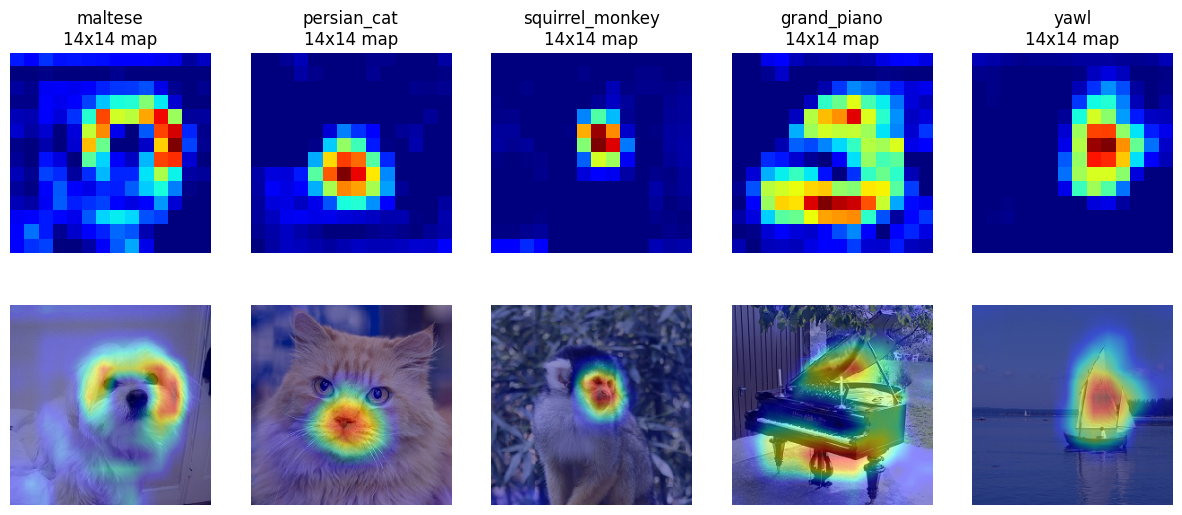

In [9]:
def grad_cam(model, img, class_index, layer_name='block5_conv3'):
    grad_model = tf.keras.models.Model(model.inputs, [model.get_layer(layer_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img[np.newaxis])
        score = preds[:, class_index]                  # 정답 범주의 점수
    grads = tape.gradient(score, conv_out)[0]          # (14, 14, 512): 특성 맵의 각 칸이 점수에 주는 영향
    weights = tf.reduce_mean(grads, axis=(0, 1))       # 특성 맵마다 기울기 평균 → 가중치 (512개)
    cam = tf.nn.relu(tf.reduce_sum(conv_out[0] * weights, axis=-1))   # 가중합 후 ReLU → (14, 14)
    cam = cam / (tf.reduce_max(cam) + 1e-8)            # 0~1로 맞추기
    return cam.numpy()

plt.figure(figsize=(15, 6))
for k, (l, i) in enumerate(zip(input_list, imagenet_index)):
    img = img_to_array(load_img('./data/img/{}_0.jpg'.format(l), target_size=(224,224)))
    cam = grad_cam(model, img, int(i))
    heat = tf.image.resize(cam[..., np.newaxis], (224, 224)).numpy()[..., 0]   # 14x14 → 224x224
    plt.subplot(2, 5, k+1); plt.imshow(cam, cmap='jet'); plt.title(f'{l}\n14x14 map'); plt.axis('off')
    plt.subplot(2, 5, k+6); plt.imshow(img.astype('uint8')); plt.imshow(heat, cmap='jet', alpha=0.45); plt.axis('off')
plt.show()

## 실습: 설정을 바꿔 보기
1. **패치 크기**: 오클루전의 `patch_size`를 20, 40, 80으로 바꿔 말티즈와 요트 사진에 적용하고, 결과 히트맵과 걸린 시간을 비교해 보세요.
2. **다른 범주**: 말티즈 사진에 대해 말티즈(153)가 아니라 페르시안 고양이(283) 범주로 Grad-CAM을 그려 보세요. 무엇이 보이나요? 이 결과가 설명 가능한 AI의 한계에 대해 무엇을 말해 주나요?
3. **다른 층**: 위의 `grad_cam` 함수에서 `layer_name`을 `'block4_conv3'`(28×28)과 `'block3_conv3'`(56×56)로 바꿔 보세요. 히트맵이 어떻게 달라지나요?

먼저 직접 작성해 본 뒤, 아래 예시 답안과 비교해 보세요.

In [10]:
# 직접 작성해 보세요



### 예시 답안

5/5 [==============================] - 1s 225ms/step
maltese  patch_size=20    1.3초
2/2 [==============================] - 0s 112ms/step
maltese  patch_size=40    0.3초
1/1 [==============================] - 0s 430ms/step
maltese  patch_size=80    0.5초
5/5 [==============================] - 0s 111ms/step
yawl     patch_size=20    0.8초
2/2 [==============================] - 0s 111ms/step
yawl     patch_size=40    0.3초
1/1 [==============================] - 0s 27ms/step
yawl     patch_size=80    0.1초


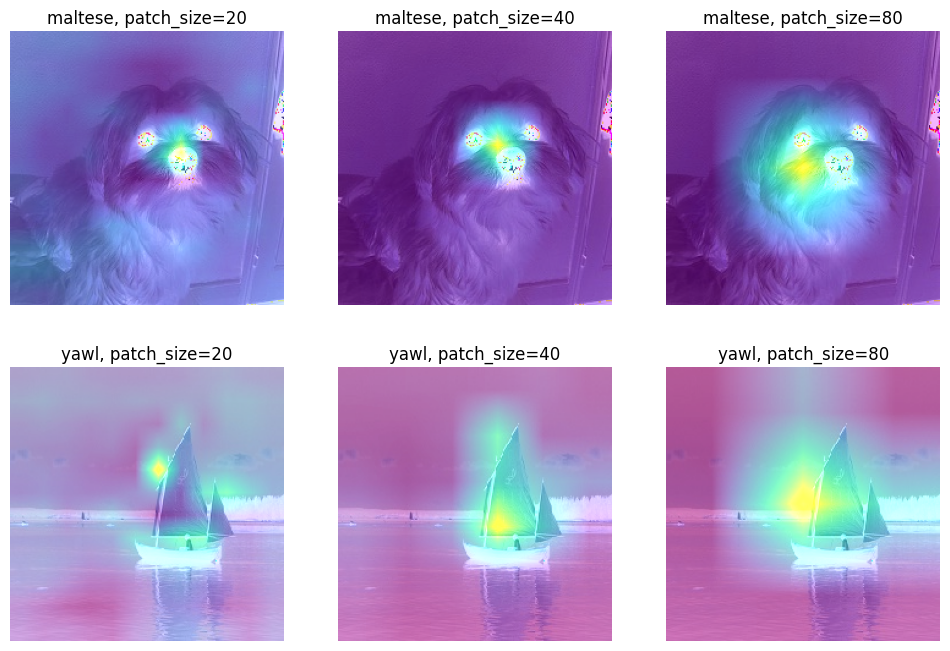

In [11]:
# 1. 패치 크기에 따른 오클루전 결과와 시간
import time
explainer = OcclusionSensitivity()
plt.figure(figsize=(12, 8))
for r, (l, i) in enumerate([('maltese', 153), ('yawl', 914)]):
    img = img_to_array(load_img('./data/img/{}_0.jpg'.format(l), target_size=(224,224)))
    for c, ps in enumerate([20, 40, 80]):
        t = time.time()
        grid = explainer.explain(([img], None), model, i, ps)
        print(f"{l:<8} patch_size={ps:<3} {time.time() - t:5.1f}초")
        plt.subplot(2, 3, r*3 + c + 1); plt.imshow(grid); plt.title(f'{l}, patch_size={ps}'); plt.axis('off')
plt.show()

> 패치 크기를 절반으로 줄이면 가릴 위치가 4배로 늘어 모델을 9번 → 36번 → 144번 실행합니다. 다만 `tf-explain`은 가린 사진들을 32장씩 묶어 한꺼번에 모델에 넣고 GPU는 한 묶음을 동시에 계산하므로, GPU에서는 시간이 실행 횟수만큼 늘지 않습니다. 게다가 처음 실행할 때나 묶음에 든 사진 수가 바뀔 때 드는 준비 시간이 섞이면, 잰 시간의 순서가 뒤바뀌기도 합니다. [런타임] → [런타임 유형 변경]에서 CPU로 바꿔 다시 재 보면 차이가 분명하게 보입니다(세션이 새로 시작되므로 맨 위 준비 셀부터 다시 실행하세요).

Maltese(153) 확률: 0.9968,  Persian cat(283) 확률: 0.000001


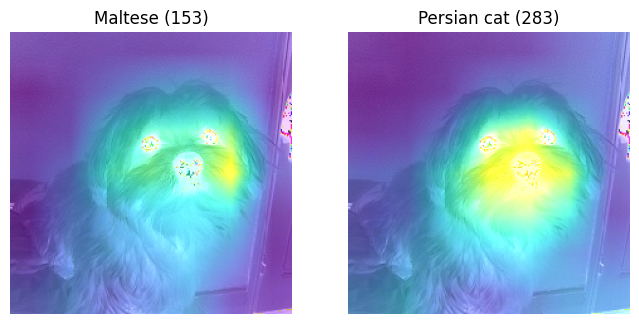

In [12]:
# 2. 말티즈 사진을 다른 범주(페르시안 고양이, 283)로 설명하기
img = img_to_array(load_img('./data/img/maltese_0.jpg', target_size=(224,224)))
p = model.predict(img[np.newaxis], verbose=0)[0]
print(f"Maltese(153) 확률: {p[153]:.4f},  Persian cat(283) 확률: {p[283]:.6f}")
explainer = GradCAM()
plt.figure(figsize=(8, 4))
for k, (name, i) in enumerate([('Maltese (153)', 153), ('Persian cat (283)', 283)]):
    grid = explainer.explain(([img], None), model, i)
    plt.subplot(1, 2, k+1); plt.imshow(grid); plt.title(name); plt.axis('off')
plt.show()

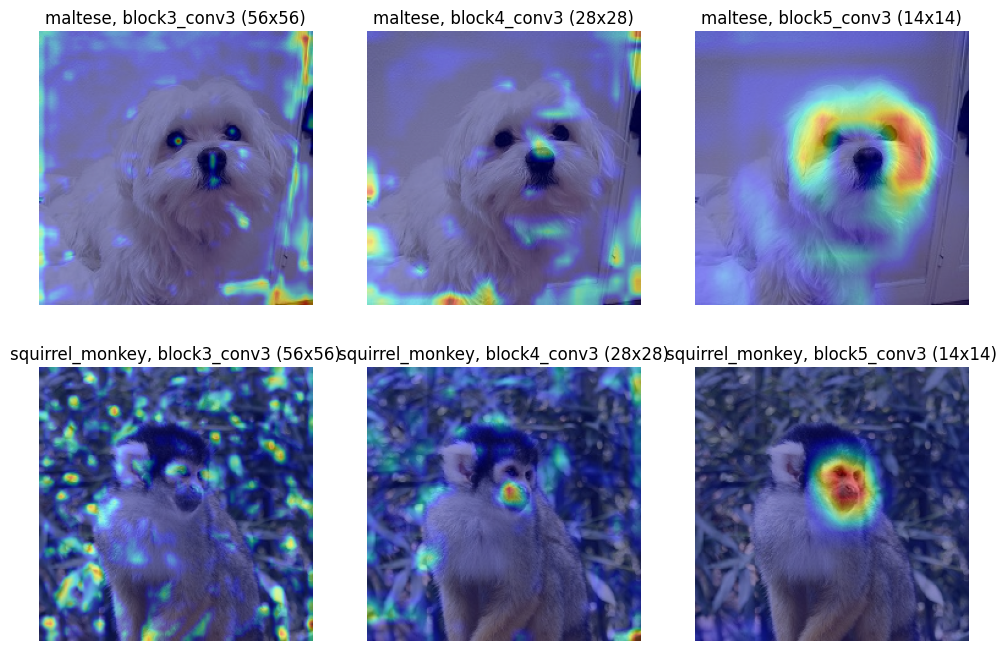

In [13]:
# 3. 층에 따른 Grad-CAM (말티즈, 다람쥐원숭이)
plt.figure(figsize=(12, 8))
for r, (l, i) in enumerate([('maltese', 153), ('squirrel_monkey', 382)]):
    img = img_to_array(load_img('./data/img/{}_0.jpg'.format(l), target_size=(224,224)))
    for c, layer in enumerate(['block3_conv3', 'block4_conv3', 'block5_conv3']):
        cam = grad_cam(model, img, i, layer)
        heat = tf.image.resize(cam[..., np.newaxis], (224, 224)).numpy()[..., 0]
        plt.subplot(2, 3, r*3 + c + 1); plt.imshow(img.astype('uint8')); plt.imshow(heat, cmap='jet', alpha=0.45)
        plt.title(f'{l}, {layer} ({cam.shape[0]}x{cam.shape[1]})'); plt.axis('off')
plt.show()